# 02 — Titanic: predictive modeling pipeline

Continues directly from `01_eda.ipynb`: it reads the **same committed `titanic.csv`** that notebook
saved (no second `sns.load_dataset` call) and re-applies the same data-independent cleaning rules from
`cleaning.py` (drop the 2 rows missing `embarked`, `deck → 'Unknown'`). Anything that *learns* from data
(age imputation, encoding, scaling) now happens inside a scikit-learn `Pipeline` fit on the training split only.

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, confusion_matrix,
                             f1_score, mean_absolute_error, mean_squared_error, precision_score,
                             r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

from cleaning import structural_clean

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RANDOM_STATE = 42

In [2]:
df = structural_clean(pd.read_csv("titanic.csv"))   # same file + same rules as 01_eda
print(df.shape)
df.head()

(889, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Unknown,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Unknown,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Unknown,Southampton,no,True


## Task 7 — Stratified train/test split (before any preprocessing)

In [3]:
NUMERIC = ["pclass", "age", "sibsp", "parch", "fare"]
CATEGORICAL = ["sex", "embarked"]
FEATURES = NUMERIC + CATEGORICAL
TARGET = "survived"
# Excluded on purpose: 'alive' (the target as text -> leakage), 'class'/'embark_town'/'who'/'adult_male'/'alone'
# (duplicates or derivations of kept columns), 'deck' (77% unknown).

X, y = df[FEATURES], df[TARGET]
print("class balance (full data):", y.value_counts(normalize=True).round(4).to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train {X_train.shape}, test {X_test.shape}")
print("train balance:", y_train.value_counts(normalize=True).round(4).to_dict())
print("test balance: ", y_test.value_counts(normalize=True).round(4).to_dict())

class balance (full data): {0: 0.6175, 1: 0.3825}
train (711, 7), test (178, 7)
train balance: {0: 0.6174, 1: 0.3826}
test balance:  {0: 0.618, 1: 0.382}


**Why stratify.** The target is imbalanced, with **38.25% survived vs 61.75% died** (about 1.6 : 1). A plain random 80/20 split could shift the survivor share of the 178-row test set by several percentage points just by chance. That would change precision, recall and F1 for reasons unrelated to the models, and make model comparisons noisy. With `stratify=y`, both splits keep the same balance (train 38.26%, test 38.20% survived). The split happens **before** any imputation, encoding or scaling, so no preprocessing step ever sees the test rows.

## Task 8 — Preprocessing fit on train only (`ColumnTransformer` inside a `Pipeline`)

In [4]:
def make_preprocessor() -> ColumnTransformer:
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))])
    return ColumnTransformer([("num", numeric, NUMERIC), ("cat", categorical, CATEGORICAL)])

# Fitting a Pipeline calls fit_transform on X_train only; predict/score on X_test calls transform only.
demo_pre = make_preprocessor().fit(X_train)
print("feature names after preprocessing:", list(demo_pre.get_feature_names_out()))
print("age median learned from TRAIN only:", demo_pre.named_transformers_["num"]["impute"].statistics_[1])
print("missing age in train / test:", X_train.age.isna().sum(), "/", X_test.age.isna().sum())

feature names after preprocessing: ['num__pclass', 'num__age', 'num__sibsp', 'num__parch', 'num__fare', 'cat__sex_male', 'cat__embarked_C', 'cat__embarked_Q', 'cat__embarked_S']
age median learned from TRAIN only: 28.0
missing age in train / test: 140 / 37


**Preprocessing choices (all fit on `X_train` only).**
- `age` (140 missing in train, 37 in test) and the other numeric features use `SimpleImputer(strategy="median")`. The median (**28.0**) is learned from the training rows only and then *applied* to test rows. This is deliberately simpler than Task 2's sex × pclass group median, because a global median from train is easy to apply to any future passenger and cannot leak test information. The tree-based models can still learn class/sex/age interactions themselves.
- `sex`, `embarked` use `SimpleImputer(most_frequent)` followed by `OneHotEncoder(handle_unknown="ignore", drop="if_binary")`, producing `sex_male` plus three `embarked_*` dummies. `embarked` has no missing values after the structural cleaning, but the imputer is kept so the saved pipeline can handle raw new data with a missing port.
- All numeric features go through `StandardScaler`.

Everything sits inside one `ColumnTransformer` wrapped in a `Pipeline` with the estimator. `Pipeline.fit(X_train, …)` runs `fit_transform` on train, and `predict(X_test)` runs `transform` only, so the structure itself guarantees that no step is ever fit or refit on test data or on the full pre-split dataset.

## Task 9 — Three classifiers on the identical split

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
}
pipes = {name: Pipeline([("pre", make_preprocessor()), ("clf", est)]).fit(X_train, y_train)
         for name, est in models.items()}

def evaluate(pipe, X_te=X_test, y_te=y_test) -> dict:
    pred = pipe.predict(X_te); proba = pipe.predict_proba(X_te)[:, 1]
    return {"accuracy": accuracy_score(y_te, pred), "precision": precision_score(y_te, pred),
            "recall": recall_score(y_te, pred), "f1": f1_score(y_te, pred),
            "roc_auc": roc_auc_score(y_te, proba)}

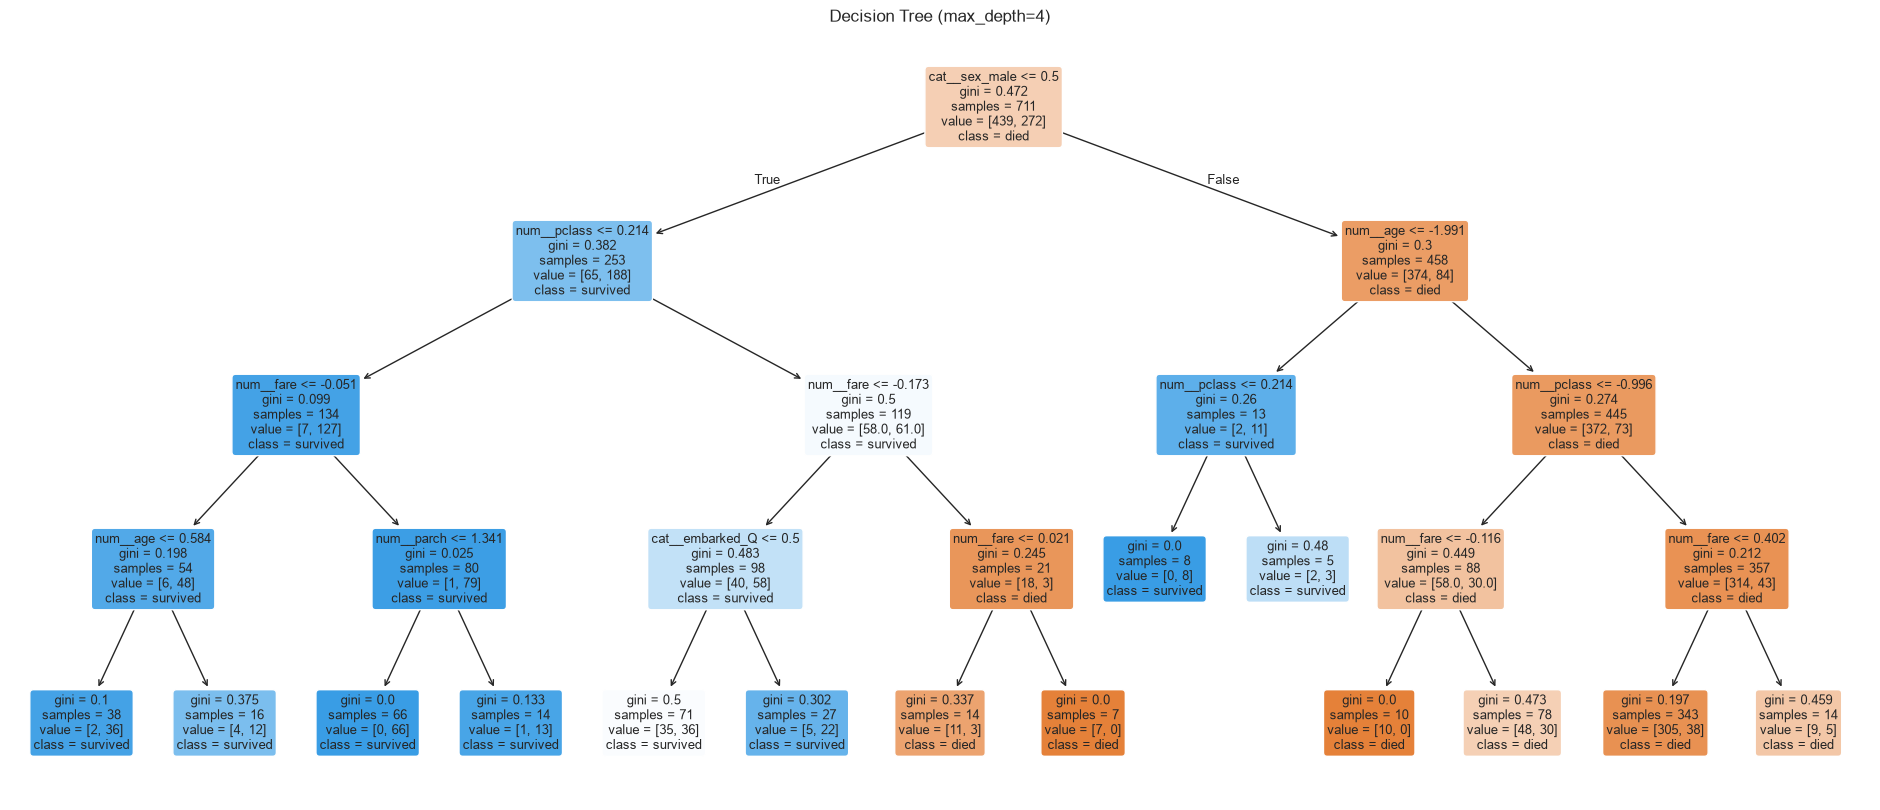

In [6]:
dt_pipe = pipes["Decision Tree"]
plt.figure(figsize=(24, 10))
plot_tree(dt_pipe.named_steps["clf"], feature_names=list(dt_pipe.named_steps["pre"].get_feature_names_out()),
          class_names=["died", "survived"], filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=4)")
plt.savefig(FIG / "09_decision_tree.png", dpi=90, bbox_inches="tight"); plt.show()

**Reading the tree.** The root split is `sex_male`, so the tree, like the EDA, finds sex the most informative variable. Females are split next by class (scaled `pclass ≤ 0.21` ⇒ 1st/2nd class) and then by fare. Males are split first by age: scaled `age ≤ −1.99` is about **3.5 years old**, and boys that young are predicted to survive. After that comes class. Depth is capped at 4 (with `min_samples_leaf=5`) so the tree stays readable and does not memorise the 711 training rows.

## Task 10 — Evaluation: confusion matrix, accuracy, precision, recall, F1, ROC/AUC

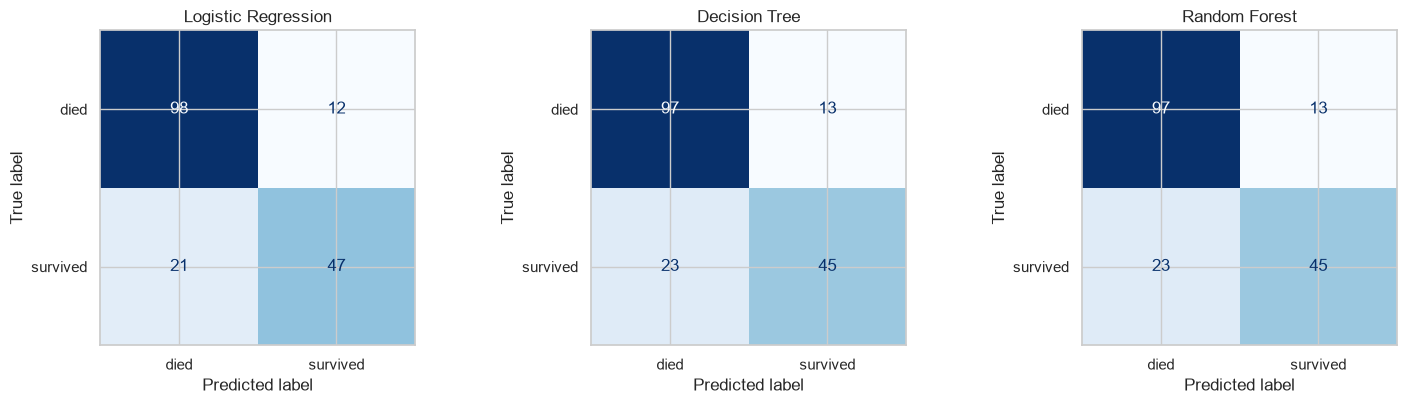

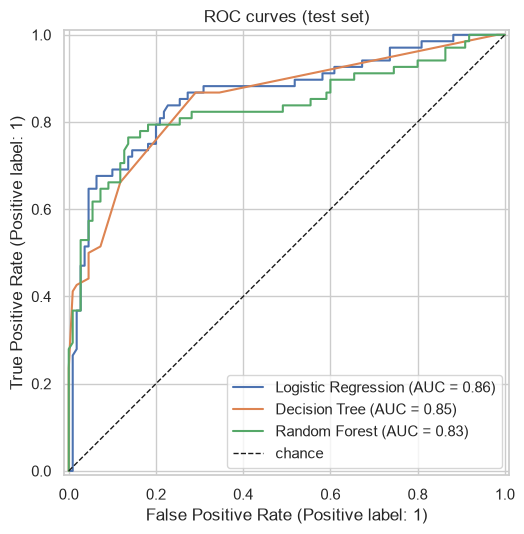

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cms = {}
for ax, (name, pipe) in zip(axes, pipes.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test)); cms[name] = cm
    ConfusionMatrixDisplay(cm, display_labels=["died", "survived"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.savefig(FIG / "10_confusion_matrices.png", dpi=110); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, pipe in pipes.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
ax.set_title("ROC curves (test set)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "11_roc_curves.png", dpi=110); plt.show()

In [8]:
clf_results = pd.DataFrame({name: evaluate(p) for name, p in pipes.items()}).T
clf_results["confusion [[TN FP] [FN TP]]"] = [str(cms[n].tolist()) for n in clf_results.index]
clf_results.round(4)

,accuracy,precision,recall,f1,roc_auc,confusion [[TN FP] [FN TP]]
Logistic Regression,0.8146,0.7966,0.6912,0.7402,0.8610,"[[98, 12], [21, 47]]"
Decision Tree,0.7978,0.7759,0.6618,0.7143,0.8510,"[[97, 13], [23, 45]]"
Random Forest,0.7978,0.7759,0.6618,0.7143,0.8348,"[[97, 13], [23, 45]]"


**Results (test set, n = 178).**

| Model | Accuracy | Precision | Recall | F1 | ROC AUC | Confusion [[TN FP] [FN TP]] |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.8146 | 0.7966 | 0.6912 | 0.7402 | **0.8610** | [[98, 12], [21, 47]] |
| Decision Tree | 0.7978 | 0.7759 | 0.6618 | 0.7143 | 0.8510 | [[97, 13], [23, 45]] |
| Random Forest | 0.7978 | 0.7759 | 0.6618 | 0.7143 | 0.8348 | [[97, 13], [23, 45]] |

Logistic Regression is best on every metric at the default 0.5 threshold. The Decision Tree and the untuned Random Forest happen to make identical hard predictions on this test set, but their probability rankings differ (AUC 0.851 vs 0.835). The untuned forest, with unlimited depth, overfits the training rows. All three models miss about a third of survivors (recall 0.66–0.69): false negatives (21–23) outnumber false positives (12–13), which fits the 38/62 class imbalance pushing borderline cases toward "died".

## Task 11 — Imbalance handling (Logistic Regression, three ways)

In [9]:
print("class balance in TRAIN:", y_train.value_counts().to_dict(),
      "->", y_train.value_counts(normalize=True).round(3).to_dict())

variants = {
    "(a) baseline": Pipeline([("pre", make_preprocessor()),
                              ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "(b) class_weight='balanced'": Pipeline([("pre", make_preprocessor()),
                              ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))]),
    # imblearn's Pipeline applies SMOTE only during fit() -> only on the training fold, never on X_test.
    "(c) SMOTE (train fold only)": ImbPipeline([("pre", make_preprocessor()),
                              ("smote", SMOTE(random_state=RANDOM_STATE)),
                              ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
}
imb_rows = {}
for name, pipe in variants.items():
    pipe.fit(X_train, y_train)
    imb_rows[name] = evaluate(pipe)
imb_results = pd.DataFrame(imb_rows).T[["precision", "recall", "f1", "accuracy", "roc_auc"]]

# proof SMOTE touched only the training data
Xt = variants["(c) SMOTE (train fold only)"].named_steps["pre"].transform(X_train)
_, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(Xt, y_train)
print("train labels after SMOTE:", pd.Series(y_res).value_counts().to_dict(), "| test set untouched:", y_test.value_counts().to_dict())
imb_results.round(4)

class balance in TRAIN: {0: 439, 1: 272} -> {0: 0.617, 1: 0.383}
train labels after SMOTE: {1: 439, 0: 439} | test set untouched: {0: 110, 1: 68}


,precision,recall,f1,accuracy,roc_auc
(a) baseline,0.7966,0.6912,0.7402,0.8146,0.8610
(b) class_weight='balanced',0.7083,0.7500,0.7286,0.7865,0.8616
(c) SMOTE (train fold only),0.7463,0.7353,0.7407,0.8034,0.8668


**Imbalance comparison (Logistic Regression, test set).** Train has 439 died / 272 survived (61.7% / 38.3%). SMOTE balanced the *training* fold to 439 / 439, and the test set stayed untouched at 110 / 68.

| Variant | Precision | Recall | F1 |
|---|---|---|---|
| (a) baseline | **0.7966** | 0.6912 | 0.7402 |
| (b) `class_weight='balanced'` | 0.7083 | **0.7500** | 0.7286 |
| (c) SMOTE (train fold only) | 0.7463 | 0.7353 | **0.7407** |

**Conclusion.** **SMOTE worked best overall.** It has the highest F1 (0.7407) and the highest ROC AUC (0.8668), and it recovers survivors (recall +4.4 points over baseline) while giving up only 5 points of precision. `class_weight='balanced'` pushes recall highest (0.75) but over-corrects, dropping precision to 0.71 and giving the lowest F1. Re-weighting moves the decision boundary for every training point, while SMOTE adds synthetic minority points only where survivors actually live in feature space. Because the imbalance is mild (38/62), all three F1 scores are within about 1 point; on 178 test rows, one passenger moves recall by 1.5 points. The practical choice depends on the cost of a missed survivor: use SMOTE (or `balanced`) when recall matters, and the baseline when precision matters.

## Task 12 — `GridSearchCV` on Random Forest (with `oob_score=True`)

In [10]:
rf_pipe = Pipeline([("pre", make_preprocessor()),
                    ("clf", RandomForestClassifier(oob_score=True, bootstrap=True,
                                                   random_state=RANDOM_STATE, n_jobs=-1))])
param_grid = {
    "clf__n_estimators": [100, 200, 400],
    "clf__max_depth": [4, 6, 8, None],
    "clf__max_features": ["sqrt", "log2", None],
}
grid = GridSearchCV(rf_pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                    scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

best_rf = grid.best_estimator_                # refit on the full training split
print("best params:      ", grid.best_params_)
print("best CV ROC-AUC:  ", round(grid.best_score_, 4))
print("OOB score (acc.): ", round(best_rf.named_steps["clf"].oob_score_, 4))
tuned_metrics = evaluate(best_rf)
pd.Series(tuned_metrics, name="Tuned RF (test)").round(4)

best params:       {'clf__max_depth': 6, 'clf__max_features': None, 'clf__n_estimators': 400}
best CV ROC-AUC:   0.8778
OOB score (acc.):  0.8129


accuracy     0.8371
precision    0.8679
recall       0.6765
f1           0.7603
roc_auc      0.8476
Name: Tuned RF (test), dtype: float64

In [11]:
pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")[
    ["param_clf__n_estimators", "param_clf__max_depth", "param_clf__max_features", "mean_test_score", "std_test_score"]
].head(8).round(4)

,param_clf__n_estimators,param_clf__max_depth,param_clf__max_features,mean_test_score,std_test_score
17,400,6,NaN,0.8778,0.0115
16,200,6,NaN,0.8766,0.0118
15,100,6,NaN,0.8760,0.0130
13,200,6,log2,0.8737,0.0160
10,200,6,sqrt,0.8737,0.0160
6,100,4,NaN,0.8734,0.0220
7,200,4,NaN,0.8734,0.0204
14,400,6,log2,0.8731,0.0142


**GridSearchCV result.** The grid covered 3 × 4 × 3 = 36 combinations × 5 stratified folds on the training split, scored by ROC AUC, with `RandomForestClassifier(oob_score=True, …)` inside the full preprocessing pipeline.
- **Best parameters:** `n_estimators = 400`, `max_depth = 6`, `max_features = None`
- **Best mean CV ROC AUC:** 0.8778
- **OOB score of the refit best forest:** **0.8129** (out-of-bag accuracy on the training split)
- Test set: accuracy 0.8371, precision 0.8679, recall 0.6765, F1 0.7603, ROC AUC 0.8476

Limiting depth to 6 is the key change against the untuned forest (unlimited depth). It stops trees from memorising individual passengers: CV ROC AUC goes 0.8752 → 0.8778, test accuracy 0.7978 → 0.8371, and test F1 0.7143 → 0.7603. With only 9 encoded features, `max_features=None` (every feature considered at every split) beat `sqrt`/`log2`, because there are too few features for random subspaces to add much useful diversity. The OOB accuracy (0.813) is close to the CV accuracy (0.830) and the test accuracy (0.837), so the forest is not overfitting.

## Task 13 — Regression side-task: predict `fare`

In [12]:
REG_NUMERIC = ["pclass", "age", "sibsp", "parch", "survived"]
REG_CATEGORICAL = ["sex", "embarked"]
REG_FEATURES = REG_NUMERIC + REG_CATEGORICAL

reg_pre = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), REG_NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), REG_CATEGORICAL),
])
reg_pipe = Pipeline([("pre", reg_pre), ("reg", LinearRegression())])

# reuse the same train/test rows as the classifiers
Xr_train, Xr_test = df.loc[X_train.index, REG_FEATURES], df.loc[X_test.index, REG_FEATURES]
yr_train, yr_test = df.loc[X_train.index, "fare"], df.loc[X_test.index, "fare"]
reg_pipe.fit(Xr_train, yr_train)
yr_pred = reg_pipe.predict(Xr_test)

n, p = len(yr_test), len(reg_pipe.named_steps["pre"].get_feature_names_out())
r2 = r2_score(yr_test, yr_pred)
reg_metrics = {"MAE": mean_absolute_error(yr_test, yr_pred),
               "RMSE": np.sqrt(mean_squared_error(yr_test, yr_pred)),
               "R2": r2, "Adjusted R2": 1 - (1 - r2) * (n - 1) / (n - p - 1)}
print(f"n_test={n}, p (predictors after encoding)={p}")
pd.Series(reg_metrics).round(4)

n_test=178, p (predictors after encoding)=9


MAE            19.7531
RMSE           41.2701
R2              0.3471
Adjusted R2     0.3122
dtype: float64

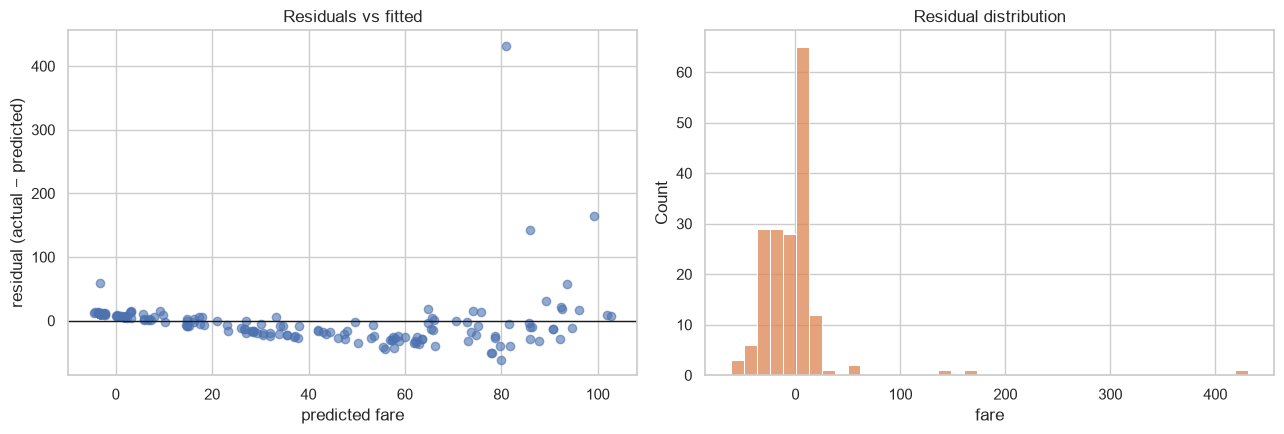

                 mean    std
fitted_tercile              
low              9.71   7.39
mid             14.32   9.26
high            35.40  59.20
corr(|residual|, fitted) = 0.324


In [13]:
resid = yr_test - yr_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(yr_pred, resid, alpha=0.6, color="#4C72B0"); axes[0].axhline(0, color="k", lw=1)
axes[0].set_xlabel("predicted fare"); axes[0].set_ylabel("residual (actual − predicted)")
axes[0].set_title("Residuals vs fitted")
sns.histplot(resid, bins=40, ax=axes[1], color="#DD8452"); axes[1].set_title("Residual distribution")
plt.tight_layout(); plt.savefig(FIG / "12_regression_residuals.png", dpi=110); plt.show()

# numeric support for the visual read: residual spread per tercile of fitted values
spread = pd.DataFrame({"fitted": yr_pred, "abs_resid": resid.abs().values})
spread["fitted_tercile"] = pd.qcut(spread.fitted, 3, labels=["low", "mid", "high"])
print(spread.groupby("fitted_tercile", observed=False)["abs_resid"].agg(["mean", "std"]).round(2))
print("corr(|residual|, fitted) =", round(np.corrcoef(spread.fitted, spread.abs_resid)[0, 1], 3))

**Regression metrics (test set, n = 178, p = 9 predictors after encoding):** MAE = **19.75**, RMSE = **41.27**, R² = **0.3471**, Adjusted R² = **0.3122**.

**Heteroscedasticity: yes.** The residual-vs-fitted plot fans out, with small, tight residuals for cheap predicted fares and a widening spread (mostly large positive residuals) as the predicted fare grows. The numbers confirm it. Mean |residual| rises from 9.71 (sd 7.39) in the lowest third of fitted values to 14.32 (sd 9.26) in the middle and 35.40 (sd 59.20) in the top third, and corr(|residual|, fitted) = 0.32. The spread of errors is therefore not constant, which breaks a key OLS assumption: coefficient standard errors are unreliable, and the model under-predicts the very expensive 1st-class fares. RMSE being twice the MAE points the same way (a few huge misses). Modeling `log(fare)` or using a tree-based regressor would be the natural next step. An R² of 0.35 means class, sex, age, family and port explain only about a third of fare variance, because fare is per ticket (shared by groups) and varies a lot within class.

## Task 14 — Final model comparison (two separate metric groups)

In [14]:
rows = {name: evaluate(p) for name, p in pipes.items()}
rows["Random Forest (tuned, GridSearchCV)"] = tuned_metrics
cls = pd.DataFrame(rows).T.rename(columns=str.title).rename(columns={"F1": "F1", "Roc_Auc": "ROC AUC"})
cls.columns = pd.MultiIndex.from_product([["Classification metrics (target: survived)"], cls.columns])

reg = pd.DataFrame({"Linear Regression (fare)": reg_metrics}).T
reg.columns = pd.MultiIndex.from_product([["Regression metrics (target: fare, GBP)"], reg.columns])

comparison = pd.concat([cls, reg]).round(4)
comparison

Classification metrics (target: survived)  \
                                                                     Accuracy   
Logistic Regression                                                    0.8146   
Decision Tree                                                          0.7978   
Random Forest                                                          0.7978   
Random Forest (tuned, GridSearchCV)                                    0.8371   
Linear Regression (fare)                                                  NaN   

                                                                       \
                                    Precision  Recall      F1 ROC AUC   
Logistic Regression                    0.7966  0.6912  0.7402  0.8610   
Decision Tree                          0.7759  0.6618  0.7143  0.8510   
Random Forest                          0.7759  0.6618  0.7143  0.8348   
Random Forest (tuned, GridSearchCV)    0.8679  0.6765  0.7603  0.8476   
Linear Regression (fare)                  NaN     NaN     NaN     NaN   

                                    Regression metrics (target: fare, GBP)  \
                                                                       MAE   
Logistic Regression                                                    NaN   
Decision Tree                                                          NaN   
Random Forest                                                          NaN   
Random Forest (tuned, GridSearchCV)                                    NaN   
Linear Regression (fare)                                           19.7531   

                                                                  
                                        RMSE      R2 Adjusted R2  
Logistic Regression                      NaN     NaN         NaN  
Decision Tree                            NaN     NaN         NaN  
Random Forest                            NaN     NaN         NaN  
Random Forest (tuned, GridSearchCV)      NaN     NaN         NaN  
Linear Regression (fare)             41.2701  0.3471      0.3122

In [15]:
print(comparison.droplevel(0, axis=1).fillna("—").to_markdown(floatfmt=".4f"))

|                                     | Accuracy   | Precision   | Recall   | F1     | ROC AUC   | MAE     | RMSE    | R2     | Adjusted R2   |
|:------------------------------------|:-----------|:------------|:---------|:-------|:----------|:--------|:--------|:-------|:--------------|
| Logistic Regression                 | 0.8146     | 0.7966      | 0.6912   | 0.7402 | 0.861     | —       | —       | —      | —             |
| Decision Tree                       | 0.7978     | 0.7759      | 0.6618   | 0.7143 | 0.851     | —       | —       | —      | —             |
| Random Forest                       | 0.7978     | 0.7759      | 0.6618   | 0.7143 | 0.8348    | —       | —       | —      | —             |
| Random Forest (tuned, GridSearchCV) | 0.8371     | 0.8679      | 0.6765   | 0.7603 | 0.8476    | —       | —       | —      | —             |
| Linear Regression (fare)            | —          | —           | —        | —      | —         | 19.7531 | 41.2701 | 0.3471 | 0.3122  

### Model selection on the training split (5-fold stratified CV)

The deployment choice is made from cross-validation on the **training** split, so the test set stays an untouched final check rather than something we select on.

In [16]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

candidates = {**pipes, "Random Forest (tuned, GridSearchCV)": best_rf}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = {}
for name, pipe in candidates.items():
    res = cross_validate(clone(pipe), X_train, y_train, cv=cv, scoring=["roc_auc", "f1", "accuracy"], n_jobs=-1)
    cv_rows[name] = {"cv_roc_auc": res["test_roc_auc"].mean(), "cv_roc_auc_std": res["test_roc_auc"].std(),
                     "cv_f1": res["test_f1"].mean(), "cv_accuracy": res["test_accuracy"].mean()}
cv_table = pd.DataFrame(cv_rows).T.sort_values("cv_roc_auc", ascending=False)
cv_table.round(4)

,cv_roc_auc,cv_roc_auc_std,cv_f1,cv_accuracy
"Random Forest (tuned, GridSearchCV)",0.8778,0.0115,0.7611,0.8298
Random Forest,0.8752,0.0149,0.7574,0.8228
Logistic Regression,0.8443,0.0367,0.7100,0.7848
Decision Tree,0.8432,0.0207,0.7040,0.7989


### Final recommendation
**Deploy the tuned Random Forest pipeline** (`n_estimators=400, max_depth=6, max_features=None`), chosen on the training split rather than the test set: it has the highest 5-fold CV ROC AUC (**0.8778 ± 0.0115**, vs 0.8443 ± 0.0367 for Logistic Regression) and the highest CV F1 (0.7611). On the held-out test set it also leads on accuracy (**0.8371**), precision (**0.8679**) and F1 (**0.7603**), and its OOB accuracy of 0.8129 agrees with those numbers. Its test ROC AUC (0.8476) is below Logistic Regression's 0.8610, but on only 178 rows that gap sits inside LR's larger CV variability, so LR remains a strong, more interpretable fallback. Its main weakness is recall (0.6765), so if missing a true survivor is the costly error, lower the decision threshold or retrain with the SMOTE variant from Task 11. The regression metrics (R² 0.347) are on a different scale and describe only how predictable `fare` is, not which classifier to deploy.

## Task 15 — Persist the complete pipeline (preprocessing + estimator) with joblib

In [17]:
best_name = cv_table.index[0]          # highest mean CV ROC-AUC on the training split
full_pipeline = candidates[best_name]
joblib.dump(full_pipeline, "titanic_best_pipeline.joblib")
print("saved:", best_name, "->", "titanic_best_pipeline.joblib")
print(full_pipeline)

saved: Random Forest (tuned, GridSearchCV) -> titanic_best_pipeline.joblib
Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['pclass', 'age', 'sibsp',
                                                   'parch', 'fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                  

In [18]:
reloaded = joblib.load("titanic_best_pipeline.joblib")

# 1) identical predictions on the raw (unpreprocessed) test rows
same = (reloaded.predict(X_test) == full_pipeline.predict(X_test)).all()
print("reloaded predictions identical to in-memory pipeline:", same,
      "| test accuracy:", round(accuracy_score(y_test, reloaded.predict(X_test)), 4))

# 2) brand-new raw passengers, including a missing age and missing embarked -> handled by the saved imputers
new_passengers = pd.DataFrame([
    {"pclass": 1, "age": 29,     "sibsp": 0, "parch": 0, "fare": 211.34, "sex": "female", "embarked": "S"},
    {"pclass": 3, "age": 24,     "sibsp": 0, "parch": 0, "fare": 7.90,   "sex": "male",   "embarked": "S"},
    {"pclass": 2, "age": np.nan, "sibsp": 1, "parch": 2, "fare": 26.00,  "sex": "female", "embarked": None},
])
new_passengers.assign(pred_survived=reloaded.predict(new_passengers),
                      p_survived=reloaded.predict_proba(new_passengers)[:, 1].round(3))

reloaded predictions identical to in-memory pipeline: True | test accuracy: 0.8371


,pclass,age,sibsp,parch,fare,sex,embarked,pred_survived,p_survived
0,1,29.0,0,0,211.34,female,S,1,0.997
1,3,24.0,0,0,7.90,male,S,0,0.068
2,2,NaN,1,2,26.00,female,NaN,1,0.837
